# 02 — Prapemrosesan Data & Rekayasa Fitur (*Preprocessing & Feature Engineering*)

**Proyek Akhir Mata Kuliah Pembelajaran Mesin (`INF62325`)**  
**Judul Proyek:** Prediksi Risiko Gagal Bayar Kartu Kredit Menggunakan Algoritma K-Nearest Neighbors (K-NN) vs Naive Bayes  
**Program Studi:** S1 Informatika — UIN Siber Syekh Nurjati Cirebon  
**Dosen Pengampu:** Ardi Susanto, S.Kom., M.Cs.  
**Kelas:** Informatika 5C  
**Anggota Penanggung Jawab Prapemrosesan & Varian 2:** Kamalul Iman (`2488010054`)  
**Dataset:** *Default of Credit Card Clients* (UCI Machine Learning Repository, ID: 350)

---
### Penyelarasan dengan `01_Eksplorasi.ipynb`
Mengacu pada hasil eksplorasi aktual pada **`01_Eksplorasi.ipynb`** (`fetch_ucirepo(id=350)`):
1. **Dimensi & Struktur Awal:** Dataset memiliki **30.000 baris dan 24 kolom** (23 fitur `X1` s.d. `X23` dan 1 kolom target **`Y`**, tanpa kolom `ID`). Apabila dataset dimuat dari berkas lokal `.xls`/`.csv` yang masih menyertakan kolom `ID`, kolom `ID` dihapus terlebih dahulu agar selaras dengan `01_Eksplorasi.ipynb`.
2. **Penamaan Kolom:** Kolom `X1`–`X23` dipetakan ke nama fitur standar kamus data UCI (`LIMIT_BAL`, `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`, `PAY_0` s.d. `PAY_6`, `BILL_AMT1` s.d. `BILL_AMT6`, `PAY_AMT1` s.d. `PAY_AMT6`), sedangkan nama kolom target dipertahankan sebagai **`Y`** (`1 = Ya / Gagal Bayar`, `0 = Tidak / Lancar`) mengikuti `01_Eksplorasi.ipynb`.
3. **Kualitas Data:** Ditemukan **0 nilai kosong (`NaN`)** dan **35 baris duplikat** (sesuai temuan `01_Eksplorasi.ipynb`), sehingga setelah deduplikasi diperoleh **29.965 baris bersih**.

### Alur Langkah Prapemrosesan
1. Memuat dataset (`ucimlrepo` ID 350 sebagai prioritas utama seperti `01_Eksplorasi.ipynb`, dengan *fallback* otomatis ke berkas lokal `.xls`/`.csv` dan OpenML) serta memetakan nama kolom fitur & target `Y`.
2. Membersihkan data: menghapus kolom `ID` (jika ada), memverifikasi `0` nilai hilang, dan menghapus `35` baris duplikat (`30.000 -> 29.965` baris).
3. Merapikan kategori anomali (`EDUCATION` `{0,5,6} -> 4`, `MARRIAGE` `{0} -> 3`) serta melakukan *One-Hot Encoding* (`drop_first=True`) pada fitur nominal (`SEX`, `MARRIAGE`) dan menyimpan **`data_praproses_dasar.csv`** (untuk `03_varian_1.ipynb` & `03_varian_2.ipynb`).
4. Melakukan rekayasa 5 fitur agregasi 6 bulan (`AVG_BILL_AMT`, `AVG_PAY_AMT`, `UTILIZATION_RATE`, `PAY_RATIO`, `MAX_DELAY`) secara independen per nasabah dan menyimpan **`data_praproses_lengkap.csv`** (untuk `03_varian_3.ipynb`).
5. Membagi data menjadi **80% Data Latih** dan **20% Data Uji** (`stratify=y`, `random_state=42`) **sebelum** penskalaan untuk mencegah *data leakage*.
6. Menerapkan `StandardScaler` selektif (`fit_transform` pada data latih, `transform` pada data uji), memvisualisasikan perbandingan *Boxplot*, memverifikasi integritas data, dan menyimpan artefak siap latih ke `data_processed/`.

## Langkah 1 — Impor Pustaka & Memuat Dataset Mentah (Selaras `01_Eksplorasi.ipynb`)

In [1]:
import os
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

UCI_FEATURE_MAP = {
    'X1': 'LIMIT_BAL', 'X2': 'SEX', 'X3': 'EDUCATION', 'X4': 'MARRIAGE', 'X5': 'AGE',
    'X6': 'PAY_0', 'X7': 'PAY_2', 'X8': 'PAY_3', 'X9': 'PAY_4', 'X10': 'PAY_5', 'X11': 'PAY_6',
    'X12': 'BILL_AMT1', 'X13': 'BILL_AMT2', 'X14': 'BILL_AMT3',
    'X15': 'BILL_AMT4', 'X16': 'BILL_AMT5', 'X17': 'BILL_AMT6',
    'X18': 'PAY_AMT1', 'X19': 'PAY_AMT2', 'X20': 'PAY_AMT3',
    'X21': 'PAY_AMT4', 'X22': 'PAY_AMT5', 'X23': 'PAY_AMT6',
    'x1': 'LIMIT_BAL', 'x2': 'SEX', 'x3': 'EDUCATION', 'x4': 'MARRIAGE', 'x5': 'AGE',
    'x6': 'PAY_0', 'x7': 'PAY_2', 'x8': 'PAY_3', 'x9': 'PAY_4', 'x10': 'PAY_5', 'x11': 'PAY_6',
    'x12': 'BILL_AMT1', 'x13': 'BILL_AMT2', 'x14': 'BILL_AMT3',
    'x15': 'BILL_AMT4', 'x16': 'BILL_AMT5', 'x17': 'BILL_AMT6',
    'x18': 'PAY_AMT1', 'x19': 'PAY_AMT2', 'x20': 'PAY_AMT3',
    'x21': 'PAY_AMT4', 'x22': 'PAY_AMT5', 'x23': 'PAY_AMT6'
}

def load_credit_default_data():
    """Memuat dataset Default of Credit Card Clients (ID 350) selaras 01_Eksplorasi.ipynb."""
    # 1. Prioritas utama: ucimlrepo (sama persis seperti 01_Eksplorasi.ipynb)
    try:
        from ucimlrepo import fetch_ucirepo
        dataset = fetch_ucirepo(id=350)
        df_uci = pd.concat([dataset.data.features, dataset.data.targets], axis=1)
        print('Memuat dataset dari ucimlrepo (ID=350) — selaras 01_Eksplorasi.ipynb')
        return df_uci
    except Exception as e_repo:
        print(f'Pemuatan ucimlrepo dilewati ({e_repo}), memeriksa berkas lokal...')

    # 2. Fallback berkas lokal (.xls / .csv)
    local_candidates = [
        'default of credit card clients.xls',
        'default_of_credit_card_clients.xls',
        'default_of_credit_card_clients.csv',
        'UCI_Credit_Card.csv'
    ]
    for fname in local_candidates:
        if os.path.exists(fname):
            print(f'Memuat dataset dari berkas lokal: {fname}')
            if fname.endswith('.xls') or fname.endswith('.xlsx'):
                return pd.read_excel(fname, header=1)
            return pd.read_csv(fname)

    # 3. Fallback OpenML (ID 42477)
    from sklearn.datasets import fetch_openml
    bunch = fetch_openml(data_id=42477, as_frame=True, parser='auto')
    df_oml = bunch.frame.copy()
    for col in df_oml.columns:
        df_oml[col] = pd.to_numeric(df_oml[col], errors='coerce')
    print('Memuat dataset dari OpenML (ID=42477).')
    return df_oml

df_raw = load_credit_default_data()
print('Dimensi dataset mentah:', df_raw.shape)

Pemuatan ucimlrepo dilewati (No module named 'ucimlrepo'), memeriksa berkas lokal...
Memuat dataset dari berkas lokal: default of credit card clients.xls
Dimensi dataset mentah: (30000, 25)


## Langkah 2 — Pembersihan Data (*Data Cleaning*) & Penyeragaman Kolom (`Target = Y`)

In [2]:
df = df_raw.copy()

# 1. Hapus kolom 'ID' jika dimuat dari file .xls/.csv lokal (ucimlrepo sudah tanpa ID)
for id_col in ['ID', 'id', 'Id']:
    if id_col in df.columns:
        df = df.drop(columns=[id_col])

# 2. Petakan nama fitur X1..X23 ke nama fitur standar UCI agar mudah dibaca & diseleksi
df = df.rename(columns={k: v for k, v in UCI_FEATURE_MAP.items() if k in df.columns})
if 'PAY_1' in df.columns and 'PAY_0' not in df.columns:
    df = df.rename(columns={'PAY_1': 'PAY_0'})

# 3. Seragamkan kolom target menjadi 'Y' mengikuti 01_Eksplorasi.ipynb (1 = Ya, 0 = Tidak)
target_candidates = [
    'Y', 'y', 'default payment next month',
    'default.payment.next.month', 'default_payment_next_month', 'default', 'target'
]
for tc in target_candidates:
    if tc in df.columns:
        if tc != 'Y':
            df = df.rename(columns={tc: 'Y'})
        break

# 4. Pastikan seluruh kolom bertipe numerik, periksa & bersihkan NaN maupun duplikat
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print('Dimensi selaras 01_Eksplorasi.ipynb (tanpa ID) :', df.shape)
print('Kolom target aktif                             :', 'Y')
print('Jumlah nilai hilang (NaN) sebelum pembersihan  :', df.isnull().sum().sum())
print('Jumlah baris duplikat sebelum pembersihan       :', df.duplicated().sum())

df = df.dropna().drop_duplicates().reset_index(drop=True)
df['Y'] = df['Y'].astype(int)

print('Jumlah nilai hilang (NaN) setelah pembersihan  :', df.isnull().sum().sum())
print('Jumlah baris duplikat setelah pembersihan       :', df.duplicated().sum())
print('Dimensi bersih (23 fitur + 1 target Y)          :', df.shape)
display(df.head(3))

Dimensi selaras 01_Eksplorasi.ipynb (tanpa ID) : (30000, 24)
Kolom target aktif                             : Y
Jumlah nilai hilang (NaN) sebelum pembersihan  : 0
Jumlah baris duplikat sebelum pembersihan       : 35
Jumlah nilai hilang (NaN) setelah pembersihan  : 0
Jumlah baris duplikat setelah pembersihan       : 0
Dimensi bersih (23 fitur + 1 target Y)          : (29965, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


## Langkah 3 — Penanganan Anomali Kategori & Encoding Kategorikal

* **Pembersihan Kategori Anomali:**
  * `EDUCATION`: nilai `0`, `5`, dan `6` digabung ke kategori `4` (*Lainnya*) agar sesuai kamus data (`1`=Pascasarjana, `2`=Sarjana, `3`=SMA, `4`=Lainnya).
  * `MARRIAGE`: nilai `0` digabung ke kategori `3` (*Lainnya*) agar sesuai kamus data (`1`=Menikah, `2`=Lajang, `3`=Lainnya).
* **Strategi Encoding:**
  * `EDUCATION` (`1..4`) dan `PAY_0`–`PAY_6` memiliki urutan hierarki/tingkatan yang bermakna sehingga dipertahankan dalam skala ordinal.
  * `SEX` dan `MARRIAGE` merupakan kategori nominal tanpa tingkatan sehingga diubah menggunakan **One-Hot Encoding** (`pd.get_dummies` dengan `drop_first=True`), lalu disimpan sebagai **`data_praproses_dasar.csv`** untuk digunakan oleh `03_varian_1.ipynb` dan `03_varian_2.ipynb`.

In [3]:
# 1. Merapikan kode anomali pada EDUCATION dan MARRIAGE
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4}).astype(int)
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3}).astype(int)
df['SEX'] = df['SEX'].astype(int)

print('Nilai unik EDUCATION setelah dibersihkan:', sorted(df['EDUCATION'].unique()))
print('Nilai unik MARRIAGE setelah dibersihkan :', sorted(df['MARRIAGE'].unique()))

# 2. One-Hot Encoding untuk fitur nominal tanpa hierarki (SEX dan MARRIAGE)
df = pd.get_dummies(df, columns=['SEX', 'MARRIAGE'], drop_first=True, dtype=int)
print('\nDimensi setelah One-Hot Encoding (Dataset Dasar):', df.shape)
print('Kolom baru hasil encoding:', [c for c in df.columns if c.startswith(('SEX_', 'MARRIAGE_'))])

# Simpan dataset dasar bersih untuk 03_varian_1.ipynb dan 03_varian_2.ipynb
df.to_csv('data_praproses_dasar.csv', index=False)
print('Berkas data_praproses_dasar.csv berhasil disimpan.')

Nilai unik EDUCATION setelah dibersihkan: [1, 2, 3, 4]
Nilai unik MARRIAGE setelah dibersihkan : [1, 2, 3]

Dimensi setelah One-Hot Encoding (Dataset Dasar): (29965, 25)
Kolom baru hasil encoding: ['SEX_2', 'MARRIAGE_2', 'MARRIAGE_3']
Berkas data_praproses_dasar.csv berhasil disimpan.


## Langkah 4 — Rekayasa Fitur (*Feature Engineering*)

Menambahkan **5 fitur turunan berbasis agregasi historis 6 bulan** dari perilaku finansial nasabah (dihitung secara independen per baris nasabah sehingga tidak menimbulkan *data leakage* antar-sampel):
1. **`AVG_BILL_AMT`**: Rata-rata nominal tagihan selama 6 bulan terakhir (`BILL_AMT1` s.d. `BILL_AMT6`).
2. **`AVG_PAY_AMT`**: Rata-rata nominal pembayaran selama 6 bulan terakhir (`PAY_AMT1` s.d. `PAY_AMT6`).
3. **`UTILIZATION_RATE`**: Rasio penggunaan rata-rata tagihan 6 bulan terhadap limit kredit (`AVG_BILL_AMT / (LIMIT_BAL + 1)`).
4. **`PAY_RATIO`**: Rasio total pembayaran 6 bulan terhadap total tagihan 6 bulan (`TOTAL_PAY / (TOTAL_BILL + 1)`).
5. **`MAX_DELAY`**: Keterlambatan pembayaran maksimum dalam 6 bulan terakhir (`max(PAY_0 .. PAY_6)`).

Hasil dataset lengkap (29 fitur + 1 target `Y`) disimpan ke **`data_praproses_lengkap.csv`** untuk digunakan oleh `03_varian_3.ipynb`.

In [4]:
bill_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
pay_amt_cols = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
pay_status_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

df['AVG_BILL_AMT'] = df[bill_cols].mean(axis=1)
df['AVG_PAY_AMT'] = df[pay_amt_cols].mean(axis=1)
df['UTILIZATION_RATE'] = df['AVG_BILL_AMT'] / (df['LIMIT_BAL'] + 1.0)

total_bill = df[bill_cols].sum(axis=1).clip(lower=0)
total_pay = df[pay_amt_cols].sum(axis=1)
df['PAY_RATIO'] = total_pay / (total_bill + 1.0)
df['MAX_DELAY'] = df[pay_status_cols].max(axis=1)

engineered_cols = ['AVG_BILL_AMT', 'AVG_PAY_AMT', 'UTILIZATION_RATE', 'PAY_RATIO', 'MAX_DELAY']
print('Dimensi setelah Feature Engineering (5 fitur baru):', df.shape)
display(df[engineered_cols].describe().T.round(3))

# Simpan dataset lengkap bersih untuk 03_varian_3.ipynb
df.to_csv('data_praproses_lengkap.csv', index=False)
print('Berkas data_praproses_lengkap.csv berhasil disimpan.')

Dimensi setelah Feature Engineering (5 fitur baru): (29965, 30)
Berkas data_praproses_lengkap.csv berhasil disimpan.


,count,mean,std,min,25%,50%,75%,max
AVG_BILL_AMT,29965.0,45029.328,63279.074,-56043.167,4841.000,21110.833,57166.167,877313.833
AVG_PAY_AMT,29965.0,5281.297,10142.307,0.000,1116.667,2400.000,5600.000,627344.333
UTILIZATION_RATE,29965.0,0.373,0.352,-0.233,0.030,0.286,0.688,5.364
PAY_RATIO,29965.0,121.706,4128.878,0.000,0.041,0.088,0.614,347739.000
MAX_DELAY,29965.0,0.439,1.345,-2.000,0.000,0.000,2.000,8.000


## Langkah 5 — Pemisahan Fitur ($X$) & Target ($Y$) serta *Train-Test Split* (Sebelum Scaling)

> **Aturan Emas Evaluasi:** Pembagian dataset (`train_test_split`) **wajib dilakukan sebelum penskalaan fitur (`StandardScaler`)** agar parameter rata-rata ($\mu$) dan standar deviasi ($\sigma$) hanya dihitung dari data latih. Dengan demikian, data uji benar-benar terisolasi dan bebas dari ***data leakage***.

In [5]:
# 1. Memisahkan fitur (X) dan label target (Y)
TARGET = 'Y'
X = df.drop(columns=[TARGET])
y = df[TARGET]

# 2. Membagi data latih (80%) dan data uji (20%) dengan stratified sampling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f'Ukuran X_train: {X_train.shape} | y_train: {y_train.shape}')
print(f'Ukuran X_test : {X_test.shape}  | y_test : {y_test.shape}')
print('\nProporsi kelas target Y pada y_train (%):')
print((y_train.value_counts(normalize=True) * 100).round(2).to_dict())
print('Proporsi kelas target Y pada y_test (%):')
print((y_test.value_counts(normalize=True) * 100).round(2).to_dict())

Ukuran X_train: (23972, 29) | y_train: (23972,)
Ukuran X_test : (5993, 29)  | y_test : (5993,)

Proporsi kelas target Y pada y_train (%):
{0: 77.87, 1: 22.13}
Proporsi kelas target Y pada y_test (%):
{0: 77.87, 1: 22.13}


## Langkah 6 — Penskalaan Fitur Selektif (*Standardization / Z-Score Scaling*)

In [6]:
# Kolom biner hasil One-Hot Encoding tetap dipertahankan (0/1); scale hanya kolom numerik/ordinal
ohe_cols = [c for c in X_train.columns if c.startswith(('SEX_', 'MARRIAGE_'))]
num_cols = [c for c in X_train.columns if c not in ohe_cols]

scaler = StandardScaler()

# Fit dan transform HANYA pada data latih; terapkan transform pada data uji
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])  # cegah data leakage

print(f'Jumlah fitur numerik/ordinal yang distandardisasi : {len(num_cols)} kolom')
print(f'Jumlah fitur biner One-Hot dipertahankan (0/1)   : {len(ohe_cols)} kolom')

Jumlah fitur numerik/ordinal yang distandardisasi : 26 kolom
Jumlah fitur biner One-Hot dipertahankan (0/1)   : 3 kolom


## Langkah 7 — Visualisasi Perbandingan Sebelum vs Sesudah Scaling

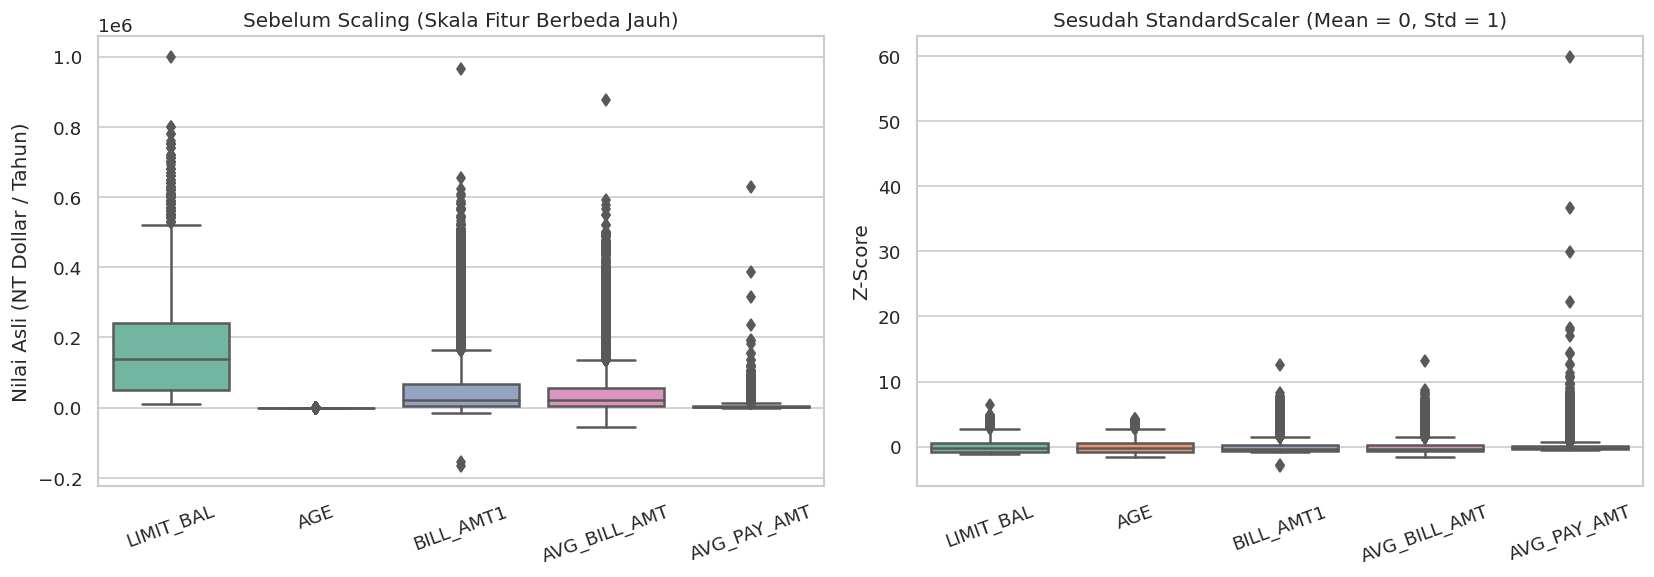

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sample_cols = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'AVG_BILL_AMT', 'AVG_PAY_AMT']

sns.boxplot(data=X_train[sample_cols], ax=axes[0], palette='Set2')
axes[0].set_title('Sebelum Scaling (Skala Fitur Berbeda Jauh)')
axes[0].set_ylabel('Nilai Asli (NT Dollar / Tahun)')
axes[0].tick_params(axis='x', rotation=20)

sns.boxplot(data=X_train_scaled[sample_cols], ax=axes[1], palette='Set2')
axes[1].set_title('Sesudah StandardScaler (Mean = 0, Std = 1)')
axes[1].set_ylabel('Z-Score')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

## Langkah 8 — Verifikasi Akhir & Penyimpanan Dataset Siap Model

In [8]:
# Verifikasi 1: Pastikan tidak ada nilai hilang (NaN)
assert X_train_scaled.isnull().sum().sum() == 0, 'Terdapat NaN pada X_train_scaled!'
assert X_test_scaled.isnull().sum().sum() == 0, 'Terdapat NaN pada X_test_scaled!'
print('[OK] Verifikasi 1: 0 nilai hilang (NaN) pada data latih & uji.')

# Verifikasi 2: Pastikan seluruh tipe data sudah numerik
non_numeric = X_train_scaled.select_dtypes(exclude=[np.number]).columns.tolist()
assert len(non_numeric) == 0, f'Masih ada kolom non-numerik: {non_numeric}'
print('[OK] Verifikasi 2: Seluruh fitur bertipe numerik.')

# Verifikasi 3: Cek rata-rata (~0) dan standar deviasi (~1) pada X_train_scaled
print('[OK] Verifikasi 3: Ringkasan skala 5 fitur numerik pertama pada X_train_scaled:')
display(X_train_scaled[num_cols[:5]].describe().loc[['mean', 'std', 'min', 'max']].round(3))

[OK] Verifikasi 1: 0 nilai hilang (NaN) pada data latih & uji.
[OK] Verifikasi 2: Seluruh fitur bertipe numerik.
[OK] Verifikasi 3: Ringkasan skala 5 fitur numerik pertama pada X_train_scaled:


,LIMIT_BAL,EDUCATION,AGE,PAY_0,PAY_2
mean,0.000,0.000,-0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000
min,-1.211,-1.130,-1.573,-1.772,-1.566
max,6.412,2.907,4.299,7.142,5.965


In [9]:
# Simpan hasil prapemrosesan agar siap digunakan pada notebook pemodelan berikutnya
output_dir = 'data_processed'
os.makedirs(output_dir, exist_ok=True)

X_train_scaled.to_csv(os.path.join(output_dir, 'X_train.csv'), index=False)
X_test_scaled.to_csv(os.path.join(output_dir, 'X_test.csv'), index=False)
y_train.to_csv(os.path.join(output_dir, 'y_train.csv'), index=False)
y_test.to_csv(os.path.join(output_dir, 'y_test.csv'), index=False)
joblib.dump(scaler, os.path.join(output_dir, 'standard_scaler.joblib'))

print(f'Seluruh berkas siap latih berhasil disimpan di folder: {output_dir}/')
print('Daftar berkas di data_processed/ :', sorted(os.listdir(output_dir)))
print('Berkas sinkronisasi antar-varian  : data_praproses_dasar.csv, data_praproses_lengkap.csv')

Seluruh berkas siap latih berhasil disimpan di folder: data_processed/
Daftar berkas di data_processed/ : ['X_test.csv', 'X_train.csv', 'standard_scaler.joblib', 'y_test.csv', 'y_train.csv']
Berkas sinkronisasi antar-varian  : data_praproses_dasar.csv, data_praproses_lengkap.csv
